# Small tabular ResNet

Architecture: encoded input → 32; two residual blocks (LayerNorm → 32-to-64 linear → GELU → dropout → 64-to-32 linear → dropout + skip connection); final LayerNorm, GELU, and one output logit. Dropout 0.2. This is a compact project-specific tabular residual network, not an image ResNet or an exact reproduction of a published benchmark.

This experiment follows the MLP protocol: fixed settings, inner-fold epoch selection, full outer-training refits, three seeds, and a same-run Logistic Regression reference. Written but not executed or tested by the assistant.

## 1. Locate the project

Use the same environment and files as the MLP notebook. In Colab the following cell mounts Drive when you execute it.

In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = None
try:
    from google.colab import drive
except ImportError:
    pass
else:
    drive.mount('/content/drive')
    PROJECT_ROOT = PROJECT_ROOT or '/content/drive/MyDrive/ADNI_capstone'
ROOT = Path(PROJECT_ROOT).expanduser().resolve() if PROJECT_ROOT else next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/scripts/deep_models.py').is_file()), None)
if ROOT is None or not (ROOT / 'src/scripts/deep_models.py').is_file():
    raise FileNotFoundError('Set PROJECT_ROOT to the updated project folder.')
print(ROOT)


/Volumes/ColdCache/untitled folder/dddd/Tables_19Sep2026


## 2. Dependencies

Skip if already installed for the MLP. Restart and rerun the path cell if installation requires a kernel restart.

In [2]:
requirements_file = str(ROOT / 'requirements-deep-learning.txt')
%pip install -r "{requirements_file}"



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 3. Fixed evaluation protocol

Keep all settings identical to the MLP except the architecture and its dropout. AdamW uses learning rate 0.001 and weight decay 0.001. Three inner folds choose a median best epoch up to 300; refitting starts from scratch on the full outer training partition. Preprocessing is fitted within the relevant training partition. The threshold is 0.5.

Seeds 42/43/44 are all reported. Seed 42 is the primary single-model run. Averaged probabilities form an explicitly separate seed ensemble. No best-seed selection, outer-label early stopping, or hyperparameter search is used. Default execution involves 180 small neural fits across all cohorts/folds/seeds.

In [3]:
import json
import pandas as pd
from IPython.display import display, Image, Markdown
sys.path.insert(0, str(ROOT / 'src/scripts'))
from deep_models import load_data, run_deep_experiment
cfg = json.loads((ROOT / 'config/deep_learning.json').read_text())
KIND = 'resnet'
REPORT = ROOT / 'reports/modeling' / cfg['run_name'] / KIND
manifest, cohorts = load_data(cfg)
display(pd.DataFrame([{'experiment': name, 'participants': len(frame), 'converters': int(frame.label.sum())} for name, frame in cohorts.items()]))
print(json.dumps(cfg, indent=2))


,experiment,participants,converters
0,clinical_reference,589,216
1,matched_clinical,222,118
2,matched_fusion,222,118


{
  "baseline_run": "artifacts/modeling/complete_cases",
  "run_name": "deep_v1",
  "experiments": [
    "clinical_reference",
    "matched_clinical",
    "matched_fusion"
  ],
  "seeds": [
    42,
    43,
    44
  ],
  "seed": 42,
  "inner_folds": 3,
  "threshold": 0.5,
  "bootstrap_repetitions": 1000,
  "device": "auto",
  "torch_threads": 1,
  "training": {
    "learning_rate": 0.001,
    "weight_decay": 0.001,
    "batch_size": 32,
    "max_epochs": 300,
    "patience": 25,
    "min_delta": 0.0001
  },
  "mlp": {
    "hidden_sizes": [
      64,
      32,
      16
    ],
    "dropout": 0.3
  },
  "resnet": {
    "width": 32,
    "hidden_width": 64,
    "blocks": 2,
    "dropout": 0.2
  },
  "tabpfn": {
    "package_version": "2.0.9",
    "model_path": "artifacts/pretrained/tabpfn-v2-classifier.ckpt",
    "checkpoint_url": "https://huggingface.co/Prior-Labs/TabPFN-v2-clf/resolve/758fe2b61e7665bb6fadd86fa6e0130a4a9b7dc4/tabpfn-v2-classifier.ckpt",
    "checkpoint_sha256": "f65a35685ae

## 4. Train

Skip this cell if this run is already complete. Existing artifacts are protected from overwrite; choose a new run_name for a deliberate new experiment.

In [4]:
results = run_deep_experiment(cfg, KIND)


resnet: clinical_reference, outer fold 1/5, seed 42
resnet: clinical_reference, outer fold 1/5, seed 43
resnet: clinical_reference, outer fold 1/5, seed 44
resnet: clinical_reference, outer fold 2/5, seed 42
resnet: clinical_reference, outer fold 2/5, seed 43
resnet: clinical_reference, outer fold 2/5, seed 44
resnet: clinical_reference, outer fold 3/5, seed 42
resnet: clinical_reference, outer fold 3/5, seed 43
resnet: clinical_reference, outer fold 3/5, seed 44
resnet: clinical_reference, outer fold 4/5, seed 42
resnet: clinical_reference, outer fold 4/5, seed 43
resnet: clinical_reference, outer fold 4/5, seed 44
resnet: clinical_reference, outer fold 5/5, seed 42
resnet: clinical_reference, outer fold 5/5, seed 43
resnet: clinical_reference, outer fold 5/5, seed 44
resnet: matched_clinical, outer fold 1/5, seed 42
resnet: matched_clinical, outer fold 1/5, seed 43
resnet: matched_clinical, outer fold 1/5, seed 44
resnet: matched_clinical, outer fold 2/5, seed 42
resnet: matched_clin

## 5. Results and seed variability

Use all seeds to assess stability. Do not treat repeated seeds as additional independent participants. Positive accuracy/AUROC/AP differences and negative Brier differences favor the neural model.

,experiment,model,participants,accuracy,precision,sensitivity,specificity,f1,balanced_accuracy,auroc,average_precision,brier_score
0,clinical_reference,logistic_regression,589,84.4%,81.0%,75.0%,89.8%,77.9%,82.4%,0.912,0.852,0.110
1,clinical_reference,resnet_seed42,589,82.9%,78.3%,73.6%,88.2%,75.9%,80.9%,0.895,0.837,0.123
2,clinical_reference,resnet_seed43,589,84.0%,80.5%,74.5%,89.5%,77.4%,82.0%,0.895,0.855,0.118
3,clinical_reference,resnet_seed44,589,85.4%,81.9%,77.3%,90.1%,79.5%,83.7%,0.899,0.841,0.114
4,clinical_reference,resnet_seed_mean,589,83.9%,80.1%,74.5%,89.3%,77.2%,81.9%,0.903,0.857,0.115
5,matched_clinical,logistic_regression,222,80.6%,81.5%,82.2%,78.8%,81.9%,80.5%,0.898,0.917,0.130
6,matched_clinical,resnet_seed42,222,79.3%,80.5%,80.5%,77.9%,80.5%,79.2%,0.859,0.861,0.151
7,matched_clinical,resnet_seed43,222,82.9%,83.3%,84.7%,80.8%,84.0%,82.8%,0.888,0.908,0.134
8,matched_clinical,resnet_seed44,222,80.2%,80.8%,82.2%,77.9%,81.5%,80.0%,0.868,0.870,0.145
9,matched_clinical,resnet_seed_mean,222,80.2%,80.8%,82.2%,77.9%,81.5%,80.0%,0.886,0.890,0.136


,experiment,model,tn,fp,fn,tp
0,clinical_reference,logistic_regression,335,38,54,162
1,clinical_reference,resnet_seed42,329,44,57,159
2,clinical_reference,resnet_seed43,334,39,55,161
3,clinical_reference,resnet_seed44,336,37,49,167
4,clinical_reference,resnet_seed_mean,333,40,55,161
5,matched_clinical,logistic_regression,82,22,21,97
6,matched_clinical,resnet_seed42,81,23,23,95
7,matched_clinical,resnet_seed43,84,20,18,100
8,matched_clinical,resnet_seed44,81,23,21,97
9,matched_clinical,resnet_seed_mean,81,23,21,97


,experiment,metric,mean,std,min,max
0,clinical_reference,accuracy,0.8410,0.0127,0.8285,0.8540
1,clinical_reference,auroc,0.8960,0.0023,0.8946,0.8987
2,clinical_reference,average_precision,0.8441,0.0095,0.8365,0.8548
3,clinical_reference,brier_score,0.1185,0.0046,0.1140,0.1231
4,clinical_reference,sensitivity,0.7515,0.0193,0.7361,0.7731
5,clinical_reference,specificity,0.8928,0.0097,0.8820,0.9008
6,matched_clinical,accuracy,0.8078,0.0188,0.7928,0.8288
7,matched_clinical,auroc,0.8717,0.0145,0.8594,0.8876
8,matched_clinical,average_precision,0.8797,0.0253,0.8608,0.9085
9,matched_clinical,brier_score,0.1433,0.0089,0.1336,0.1511


,experiment,model,reference,metric,difference,lower_95,upper_95,bootstrap_samples
0,clinical_reference,resnet_seed42,logistic_regression,auroc,-0.0174,-0.0294,-0.0056,1000
1,clinical_reference,resnet_seed42,logistic_regression,average_precision,-0.0155,-0.0406,0.0139,1000
2,clinical_reference,resnet_seed42,logistic_regression,brier_score,0.0134,0.0054,0.0214,1000
3,clinical_reference,resnet_seed42,logistic_regression,accuracy,-0.0153,-0.0323,0.0017,1000
4,clinical_reference,resnet_seed_mean,logistic_regression,auroc,-0.0086,-0.0193,0.0022,1000
5,clinical_reference,resnet_seed_mean,logistic_regression,average_precision,0.0046,-0.0188,0.0297,1000
6,clinical_reference,resnet_seed_mean,logistic_regression,brier_score,0.0054,-0.0007,0.0122,1000
7,clinical_reference,resnet_seed_mean,logistic_regression,accuracy,-0.0051,-0.0170,0.0068,1000
8,matched_clinical,resnet_seed42,logistic_regression,auroc,-0.0389,-0.0661,-0.0141,1000
9,matched_clinical,resnet_seed42,logistic_regression,average_precision,-0.0564,-0.1020,-0.0172,1000


,experiment,outer_fold,seed,inner_best_epochs,refit_epochs,encoded_input_columns,trainable_parameters
0,clinical_reference,1,42,"[15, 8, 7]",8,18,9217
1,clinical_reference,1,43,"[15, 6, 6]",6,18,9217
2,clinical_reference,1,44,"[9, 6, 6]",6,18,9217
3,clinical_reference,2,42,"[16, 14, 12]",14,18,9217
4,clinical_reference,2,43,"[9, 6, 7]",7,18,9217
5,clinical_reference,2,44,"[8, 12, 8]",8,18,9217
6,clinical_reference,3,42,"[11, 11, 11]",11,18,9217
7,clinical_reference,3,43,"[9, 6, 8]",8,18,9217
8,clinical_reference,3,44,"[11, 8, 7]",8,18,9217
9,clinical_reference,4,42,"[10, 11, 11]",11,18,9217


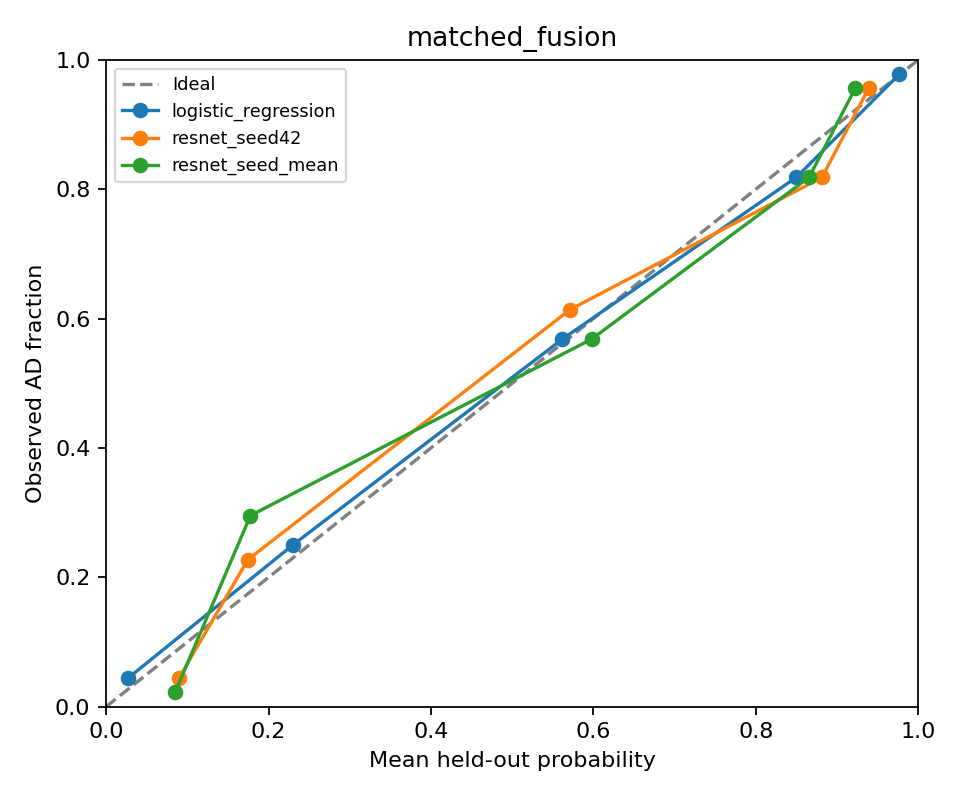

# Exploratory resnet results

| Experiment | Model | N | Accuracy | AUROC | AP | Brier |
|---|---|---:|---:|---:|---:|---:|
| clinical_reference | logistic_regression | 589 | 84.4% | 0.912 | 0.852 | 0.110 |
| clinical_reference | resnet_seed42 | 589 | 82.9% | 0.895 | 0.837 | 0.123 |
| clinical_reference | resnet_seed43 | 589 | 84.0% | 0.895 | 0.855 | 0.118 |
| clinical_reference | resnet_seed44 | 589 | 85.4% | 0.899 | 0.841 | 0.114 |
| clinical_reference | resnet_seed_mean | 589 | 83.9% | 0.903 | 0.857 | 0.115 |
| matched_clinical | logistic_regression | 222 | 80.6% | 0.898 | 0.917 | 0.130 |
| matched_clinical | resnet_seed42 | 222 | 79.3% | 0.859 | 0.861 | 0.151 |
| matched_clinical | resnet_seed43 | 222 | 82.9% | 0.888 | 0.908 | 0.134 |
| matched_clinical | resnet_seed44 | 222 | 80.2% | 0.868 | 0.870 | 0.145 |
| matched_clinical | resnet_seed_mean | 222 | 80.2% | 0.886 | 0.890 | 0.136 |
| matched_fusion | logistic_regression | 222 | 83.8% | 0.906 | 0.919 | 0.124 |
| matched_fusion | resnet_seed42 | 222 | 82.4% | 0.896 | 0.896 | 0.130 |
| matched_fusion | resnet_seed43 | 222 | 80.2% | 0.883 | 0.883 | 0.142 |
| matched_fusion | resnet_seed44 | 222 | 78.8% | 0.896 | 0.902 | 0.142 |
| matched_fusion | resnet_seed_mean | 222 | 80.2% | 0.902 | 0.907 | 0.131 |

## Interpretation

- The first configured seed (42) is the prespecified single-model result, not the best seed.
- The seed_mean row averages probabilities from all configured seeds. It is a separate seed ensemble, not the mean of the accuracy scores.
- Seed variability describes repeated fitting on the same participants. Seeds are not independent patient samples.
- The fixed Logistic Regression reference is refitted in the same environment on identical outer folds.
- Architecture, optimizer settings, and threshold were fixed. MLP/ResNet inner folds select training duration only; final models refit on the full outer training set.
- TabPFN uses a pinned pretrained model and no task-specific gradient optimization; this is not training a transformer from scratch.
- AP is non-interpolated average precision. Metric CSV rates use 0-1 scales; confusion counts are counts.
- Paired intervals condition on saved predictions, omit full retraining uncertainty, and are not adjusted for multiple comparisons.
- Previously inspected cohorts make this exploratory. Do not select the best result and call it independent confirmation.
- Broader clinical and matched cohorts are different populations. The matched cohort is ADNI1 only; labels remain provisional.
- Complete-case selection, unresolved outcomes, unavailable MRI/CSF comparisons, and no external validation remain limitations.


In [5]:
results = pd.read_csv(REPORT / 'metrics.csv')
columns = ['experiment', 'model', 'participants', 'accuracy', 'precision', 'sensitivity', 'specificity', 'f1', 'balanced_accuracy', 'auroc', 'average_precision', 'brier_score']
formats = {c: '{:.1%}' for c in ['accuracy', 'precision', 'sensitivity', 'specificity', 'f1', 'balanced_accuracy']}
formats.update({c: '{:.3f}' for c in ['auroc', 'average_precision', 'brier_score']})
display(results[columns].style.format(formats))
display(results[['experiment', 'model', 'tn', 'fp', 'fn', 'tp']])
display(pd.read_csv(REPORT / 'seed_variability.csv').round(4))
display(pd.read_csv(REPORT / 'paired_vs_logistic.csv').round(4))
display(pd.read_csv(REPORT / 'training_epochs.csv'))
display(Image(filename=str(REPORT / 'calibration_matched_fusion.png')))
display(Markdown((REPORT / 'results.md').read_text()))


## Decision

Compare with the MLP and original baseline within each cohort. The additional residual blocks are useful only if the actual results justify them. This dataset has already informed modeling choices, so no result here is an independent final confirmation.

The report includes parameter counts rather than assuming a literature estimate applies exactly. MLP/ResNet explanations are future work; do not attach the earlier LR/XGBoost SHAP plots to these models. For the third experiment, use `05_tabpfn.ipynb` in its separate pinned environment.